# **Carol Farah - Daniel Keren - Mariana Montoya**

Parts of the Spike:

1. Spikes
2. Drift
3. Noise

How to model them?

Seldom random in Python, by setting a seed. For this simulation we will use seed 42.

Try to reproduce the graph and create a script.


For the Drift:
* We will assume is a wave and is cyclical

What are we going to model:

* Spikes: Firing rate - Poisson - Lambda (**# Spikes**) / How to model the differents windows of spike rates? (Activity window **Spike location**) . Bayesian Model - Assumption (We do not have the information)

* Drift:
* Noise:

Code

Output

Distribution


# Thought Process

To tackle the issue at hand, which requires us to reverse engineer a signal from a neuron, we decided to replicate each element at a time:

1. Spike Count
2. Spike Location
3. Drift
4. Random noise

# **Spike Count and Locations**



We looked at the original data and extracted the spike count from the signal, there were 42 spikes. Given that the task at hand requires us to replicate spike count in a specific time interval, we decided to base our solution on Poisson distribution.

And to specify location of each spike, we decided to split the 10 seconds into two 5 second halves, because a test on bin widths showed 5 s was the best way to split it without overfitting. We counted the spikes in each half: 23 in the first, 19 in the second, giving us two parameters of lambda1 = 4.6 hz in the first 5 seconds, and lambda2 = 3.8 hz in the second. We then generated two poisson distributions ( t= 0s -> t = 5s with lambda = 4.6 hz, t = 5s -> t = 10s with lambda = 3.8 hz), we also didn't let two spikes come closer than 5 ms, like a real neuron. the outcome gave us a close estimation of spike count and locations in the signal.

As for their shape, every real spike looks about the same. It jumps to about 5 and fades away within a few milliseconds. We measured that shape and gave every fake spike the same one.


In [ ]:
import sys
from pathlib import Path

import numpy as np
from scipy.optimize import curve_fit

sys.path.insert(0, str(Path(__file__).resolve().parent.parent / "Part 5"))
from common import (REFRACTORY_MS, THRESHOLD, baseline, detect_spikes, load, refractory_samples_from,  # noqa: E402
                    sampling_interval)

PEAK_SEARCH = 5
FIT_SAMPLES = 8
KERNEL_TAUS = 6
WINDOW_S = 5.0
SEED = 0


def detected_spikes():
    t, x = load()
    y = x - baseline(t, x)
    idx = detect_spikes(x, THRESHOLD, refractory_samples_from(t, REFRACTORY_MS))
    peaks = np.array([i + np.argmax(y[i:i + PEAK_SEARCH]) for i in idx], dtype=int)
    return t, y, peaks


def decay(n, amplitude, tau):
    return amplitude * np.exp(-n / tau)


def fit_waveform(y, peaks, dt):
    peaks = peaks[peaks + FIT_SAMPLES <= y.size]
    mean = np.array([y[p:p + FIT_SAMPLES] for p in peaks]).mean(axis=0)
    (amplitude, tau), _ = curve_fit(decay, np.arange(FIT_SAMPLES), mean, p0=(5, 3))
    return amplitude, tau * dt


def window_edges(duration, width):
    # A width that doesn't divide the recording leaves a shorter last window.
    return np.append(np.arange(0, duration - 1e-9, width), duration)


def window_rates(spike_times, edges):
    return np.histogram(spike_times, edges)[0] / np.diff(edges)


def poisson_times(rates, edges, dead_time, rng):
    # Constant rate inside each window; spikes closer than dead_time to the last kept one are dropped,
    # the same rule the detector uses.
    times = np.sort(np.concatenate([rng.uniform(lo, hi, rng.poisson(r * (hi - lo)))
                                    for r, lo, hi in zip(rates, edges[:-1], edges[1:])]))
    kept = []
    for s in times:
        if not kept or s - kept[-1] >= dead_time:
            kept.append(s)
    return np.array(kept)


def simulate(spike_times, duration, window_s, dead_time, rng):
    edges = window_edges(duration, window_s)
    rates = window_rates(spike_times, edges)
    return rates, poisson_times(rates, edges, dead_time, rng)


def spike_train(spike_times, n_samples, dt, amplitude, tau):
    impulses = np.zeros(n_samples)
    np.add.at(impulses, np.round(spike_times / dt).astype(int).clip(0, n_samples - 1), 1)
    kernel = decay(np.arange(int(KERNEL_TAUS * tau / dt)), amplitude, tau / dt)
    return np.convolve(impulses, kernel)[:n_samples]


def recording():
    t, y, peaks = detected_spikes()
    dt = sampling_interval(t)
    return t, y, peaks, dt, t.size * dt

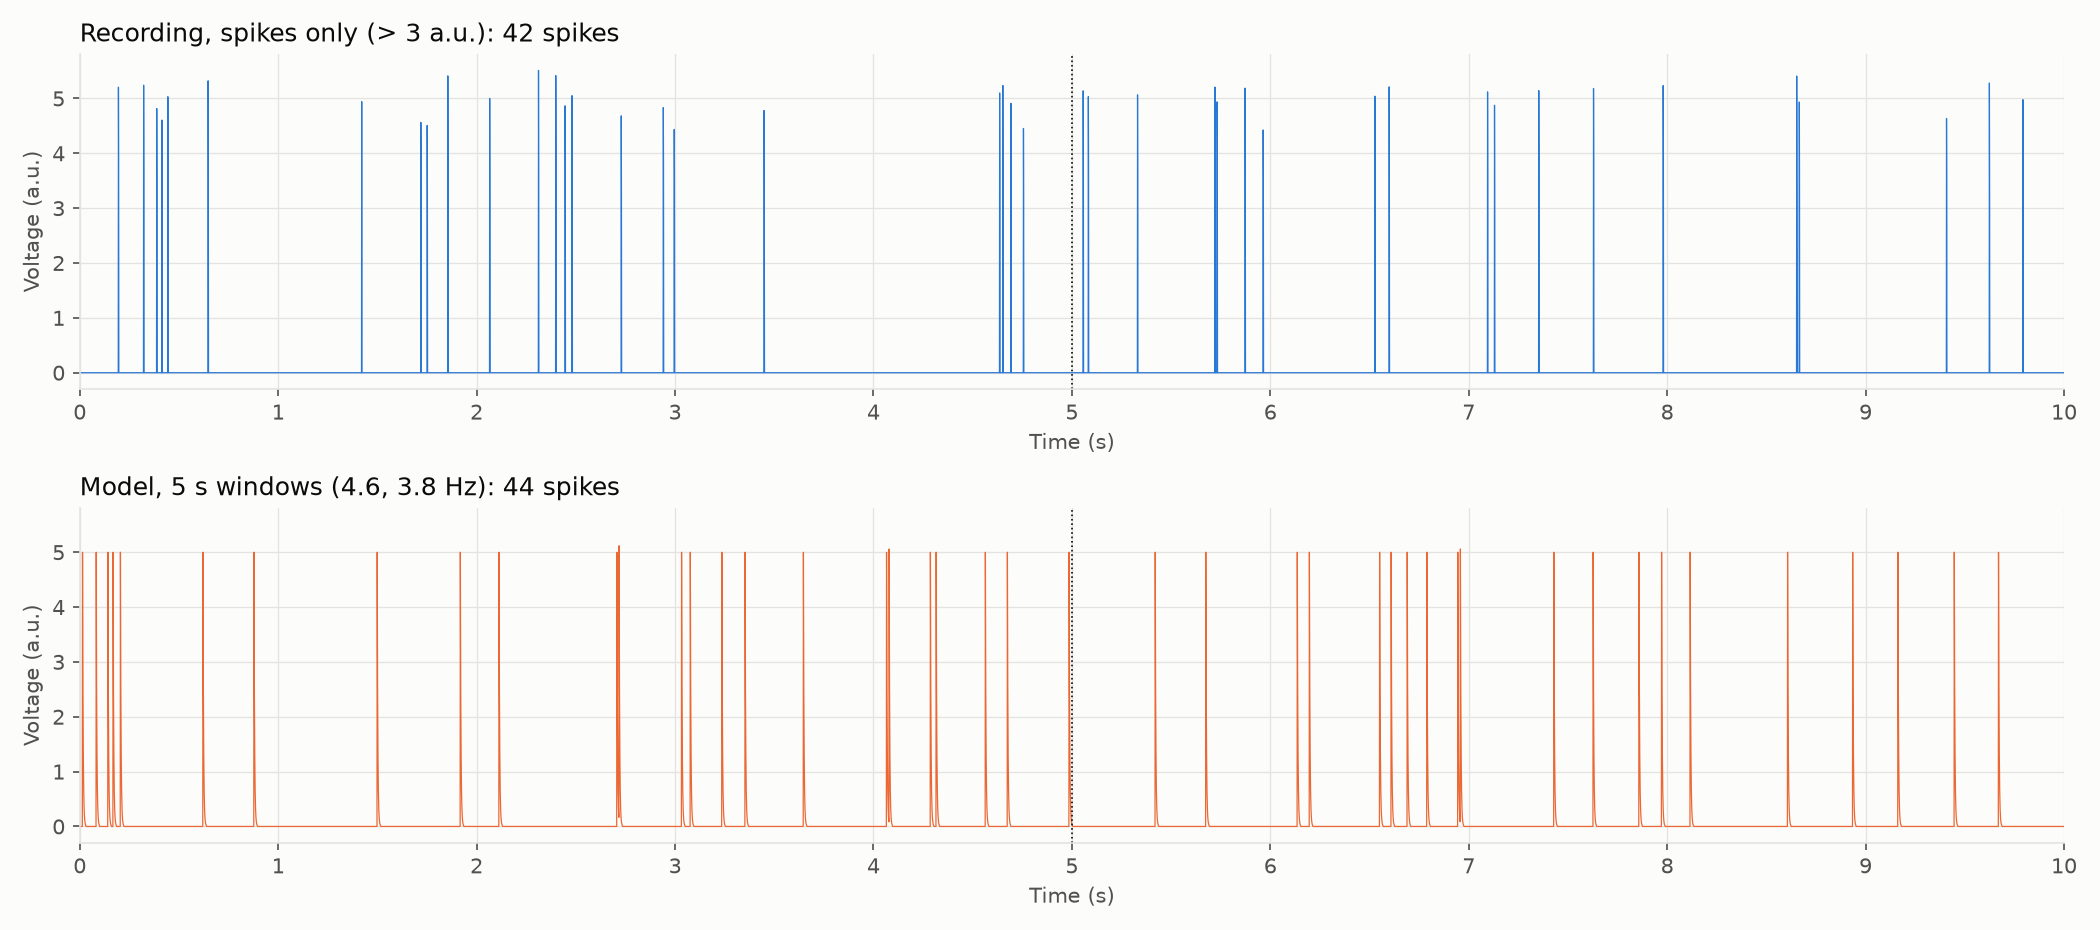

# **Drift**


Drift model

We made an assumption that the drift in the recording was a sine wave. We then measured the amplitude, frequency and phase of the drift via this model:

D(t) = A * sin(2 * pi * f * t + phase) + c.

A is the amplitude, f the frequency, phase where the wave starts at t = 0, and c the offset.

We first thought of conducting FFT to extract the parameters, however due to the length of the recording (t = 10s), FFT can only tell frequencies at steps of 1/t = 1/10 s. and given that the recording doesn't hold a full cycle in the time interval, we thought that it's best to settle for FFT.

Another option that we considered is using the running median of the data, which is essentially a smoothed signal of the data using the median of a sliding window. However, the running median is already a smoothed estimate of the baseline, so a fit to it carries its errors. Nevertheless, we used the running median signal as a measure for comparisson for future use.

To determine the parameters, The sine was fitted with curve_fit directly to the raw voltage, after removing the samples around every detected
spike (2 samples before to 12 samples after each of the 42 spikes, 584 samples in total). The spikes are far above
the baseline, so leaving them in would pull the fit up. The noise has a mean of 0, so it doesn't bias the fit. The following table shows a summary of the results:


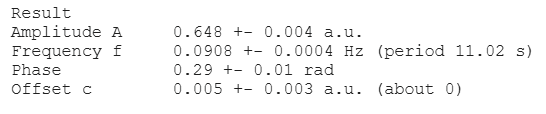


To validate our results, we subtracted the sine from the recording and measured the residual standard deviation (SD). With spikes masked, the residual has an SD of 0.298 a.u.—matching the noise SD of 0.30 established in Part 5 of the previous assignment, and a mean of 0.00 in both halves of the recording. This confirms the sine model successfully removes the baseline drift, leaving only background noise.


Limits
The recording covers only about 0.9 of a cycle, so the frequency and phase are partly traded off against each other
in the fit. The period of 11 s is an estimate from less than one cycle. A 3rd-order polynomial fits the drift equally
well (residual SD 0.300), so the data alone doesn't prove the drift is a sine; the sine was chosen because it is
simple and its parameters (amplitude and period) have a clear meaning.
Mostrando drift_model_explaination.txt.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

sys.path.insert(0, str(Path(__file__).resolve().parents[2] / "Part 5"))
from common import (BASELINE_WINDOW_MS, DETRENDED_COLOR, RAW_COLOR, REFRACTORY_MS, SURFACE, TEXT_PRIMARY,  # noqa: E402
                    THRESHOLD, baseline, detect_spikes, load, refractory_samples_from, style_axis)

HERE = Path(__file__).resolve().parent
# Samples removed around each detected spike: from just before the onset to past the end of the decay (tau ~3 ms).
MASK_BEFORE = 2
MASK_AFTER = 12
P0 = (0.65, 0.1, 0.0, 0.0)
PANEL_HEIGHT = 2.8
X_TICK_STEP = 1
# Fixed range that fits the raw voltage (-1.7 to 6.2), so every drift panel is on the same scale as the full data.
YLIM = (-2, 6.5)


def sine(t, amplitude, frequency, phase, offset):
    return amplitude * np.sin(2 * np.pi * frequency * t + phase) + offset


def spike_mask(n_samples, idx):
    keep = np.ones(n_samples, bool)
    for i in idx:
        keep[max(0, i - MASK_BEFORE):i + MASK_AFTER] = False
    return keep


def fit_drift(t, x, keep):
    params, cov = curve_fit(sine, t[keep], x[keep], p0=P0)
    return params, np.sqrt(np.diag(cov))


def main():
    t, x = load()
    idx = detect_spikes(x, THRESHOLD, refractory_samples_from(t, REFRACTORY_MS))
    keep = spike_mask(t.size, idx)
    (amplitude, frequency, phase, offset), (e_a, e_f, e_p, e_c) = fit_drift(t, x, keep)
    drift = sine(t, amplitude, frequency, phase, offset)
    real = baseline(t, x)
    residual = x - drift

    print(f"Samples used          {keep.sum()} of {t.size} ({(~keep).sum()} masked around {idx.size} spikes)")
    print(f"Amplitude A           {amplitude:.3f} ± {e_a:.3f} a.u.")
    print(f"Frequency f           {frequency:.4f} ± {e_f:.4f} Hz (period {1 / frequency:.2f} s)")
    print(f"Phase                 {phase:.2f} ± {e_p:.2f} rad")
    print(f"Offset c              {offset:.3f} ± {e_c:.3f} a.u.")
    print(f"Residual SD           {residual[keep].std():.3f} a.u. (spikes masked)")
    for lo, hi in [(0, 5), (5, 10)]:
        part = keep & (t >= lo) & (t < hi)
        print(f"Residual mean {lo}-{hi} s".ljust(22) + f"{residual[part].mean():.3f} a.u.")

    print(f"Model vs running median   mean difference {(drift - real).mean():.3f} a.u., "
          f"largest {np.abs(drift - real).max():.3f} a.u.")

    model_title = (f"Drift model: {amplitude:.3f} sin(2\u03c0 \u00b7 {frequency:.4f} t + {phase:.2f}) + {offset:.3f}  "
                   f"(period {1 / frequency:.2f} s)")
    real_title = f"Recording drift: {BASELINE_WINDOW_MS} ms running median of the raw voltage"

    fig, ax = plt.subplots(figsize=(14, PANEL_HEIGHT + 0.6), facecolor=SURFACE)
    ax.plot(t, drift, color=DETRENDED_COLOR, linewidth=1.8)
    finish(ax, t, model_title)
    save(fig, "drift_fit.png")

    raw_title = "Recording, full raw voltage"
    fig, axes = plt.subplots(3, 1, figsize=(14, PANEL_HEIGHT * 3 + 0.6), facecolor=SURFACE)
    axes[0].plot(t, x, color=RAW_COLOR, linewidth=0.6)
    finish(axes[0], t, raw_title)
    axes[1].plot(t, real, color=RAW_COLOR, linewidth=1.8)
    finish(axes[1], t, real_title)
    axes[2].plot(t, drift, color=DETRENDED_COLOR, linewidth=1.8)
    finish(axes[2], t, model_title)
    save(fig, "drift_side_by_side.png")

    fig, ax = plt.subplots(figsize=(14, PANEL_HEIGHT + 0.6), facecolor=SURFACE)
    ax.plot(t, x, color=RAW_COLOR, linewidth=0.6, label="Recording, full raw voltage")
    ax.plot(t, drift, color=DETRENDED_COLOR, linewidth=1.8, label="Drift model (fitted sine)")
    finish(ax, t, "Recording (full raw voltage) vs drift model")
    ax.legend(loc="upper right", frameon=False, ncol=2, fontsize=8)
    save(fig, "drift_overlay.png")


def finish(ax, t, title):
    ax.set_title(title, color=TEXT_PRIMARY, loc="left")
    ax.set_xlim(t[0], t[-1] + (t[1] - t[0]))
    ax.set_xticks(np.arange(0, t[-1] + X_TICK_STEP, X_TICK_STEP))
    ax.set_ylim(*YLIM)
    style_axis(ax, "Time (s)", "Voltage (a.u.)")


def save(fig, name):
    fig.tight_layout()
    fig.savefig(HERE / name, dpi=150)
    print(f"Saved {name}")


if __name__ == "__main__":
    main()
Mostrando drift_model_explaination.txt.

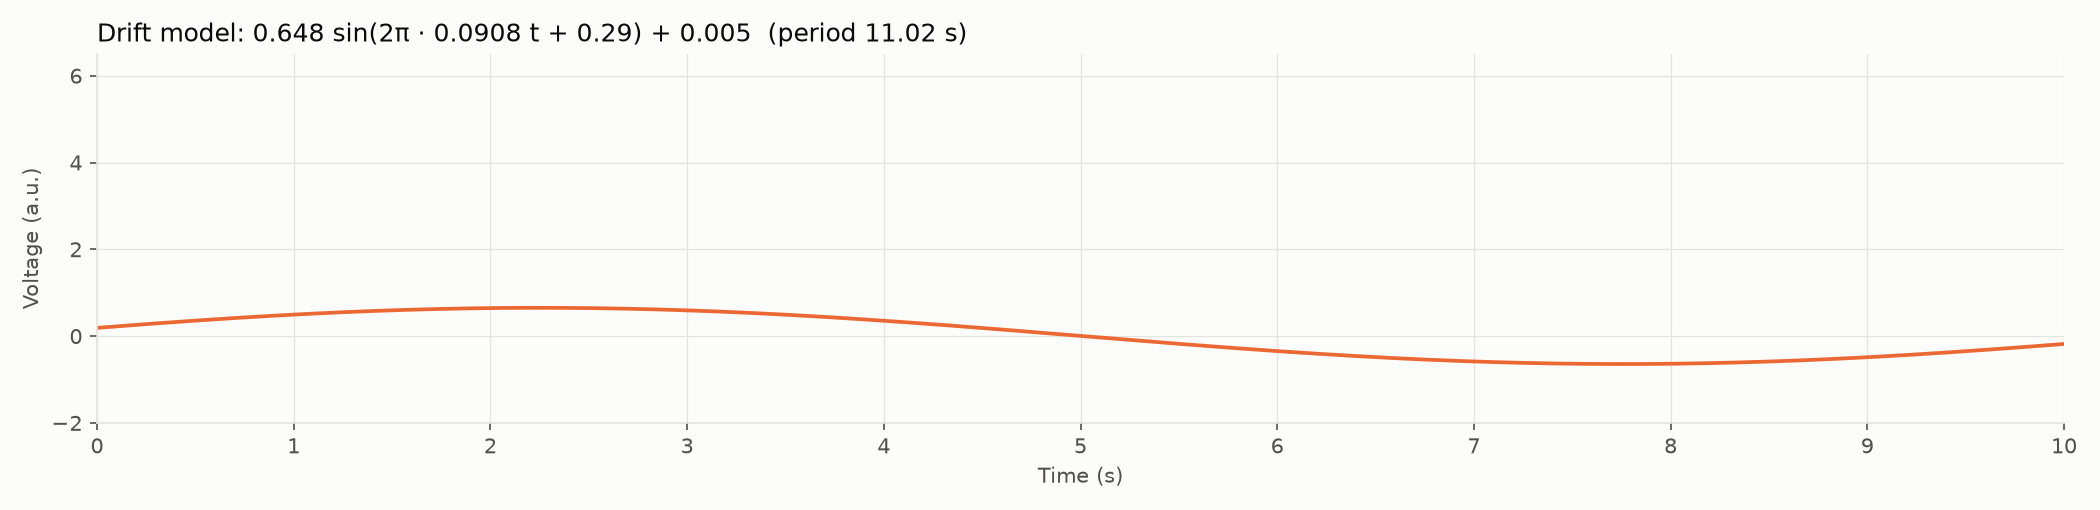

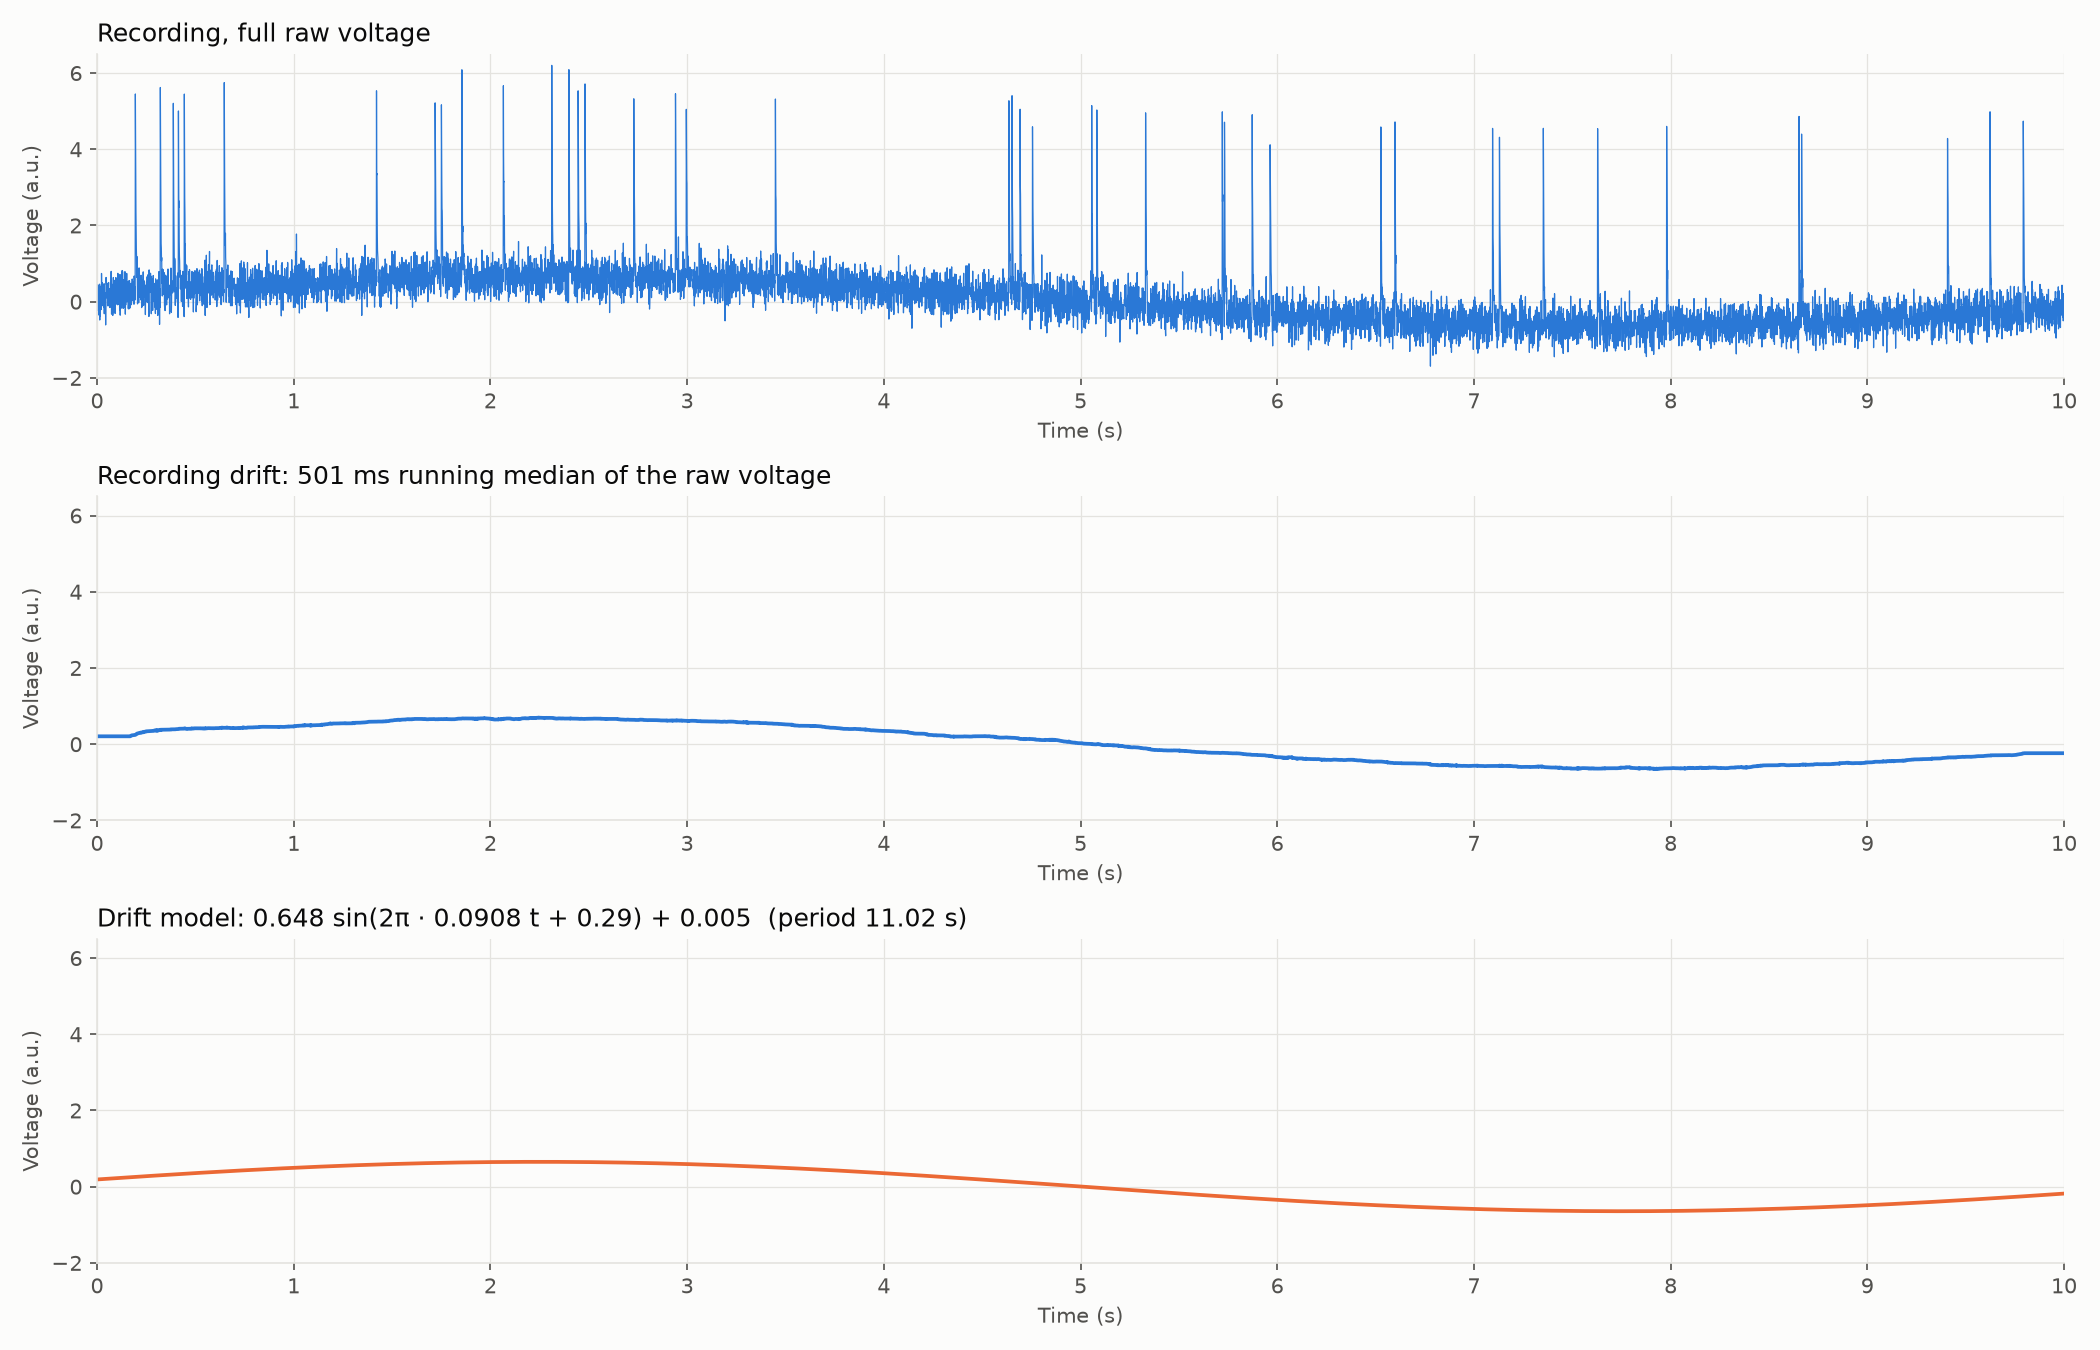

Compared with the recording drift as seen below, the recording drift here is the 501 ms running median of the raw voltage (the same baseline as in Part 5 of the previous assignment).
The sine stays close to it: mean difference -0.015 a.u., largest difference 0.080 a.u. The largest differences are
at the very start and end, where the running median is flat because it pads the edges.

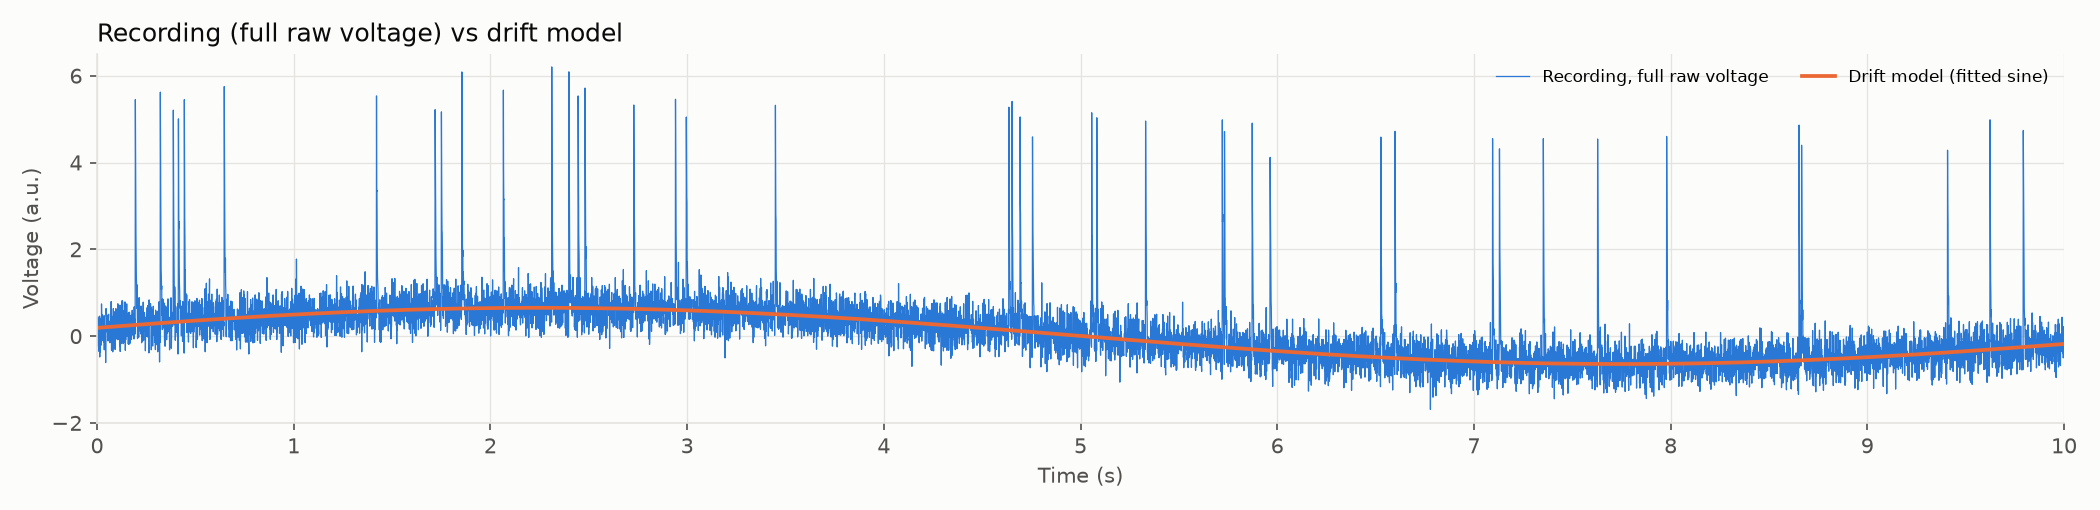

# **Noise**

Noise model

The background noise was modeled as zero-mean Gaussian white noise, where each sample represents an independent draw from a normal distribution with mean = 0 and standard deviation sigma. For computational reproducibility, simulated noise draws used a fixed pseudorandom seed (seed = 42).To isolate the noise trace, both the fitted baseline drift and the identified action potential spikes were subtracted (masked) from the raw signal, where the noise parameter was calculated directly from this residual, providing us wuth sigma = 0.298.

The choice of a stationary Gaussian white noise model was validated across three criteria:

Shape: skewness = 0.03 and excess kurtosis = -0.03, which were similar to the values in a normal distribution  where skewness = 0.0 and excess kurtosis = 0.0.
Two normality tests find no evidence against a Gaussian (D'Agostino-Pearson p = 0.47, Kolmogorov-Smirnov p = 0.99). The histogram below demonstrates similarities in the shape.

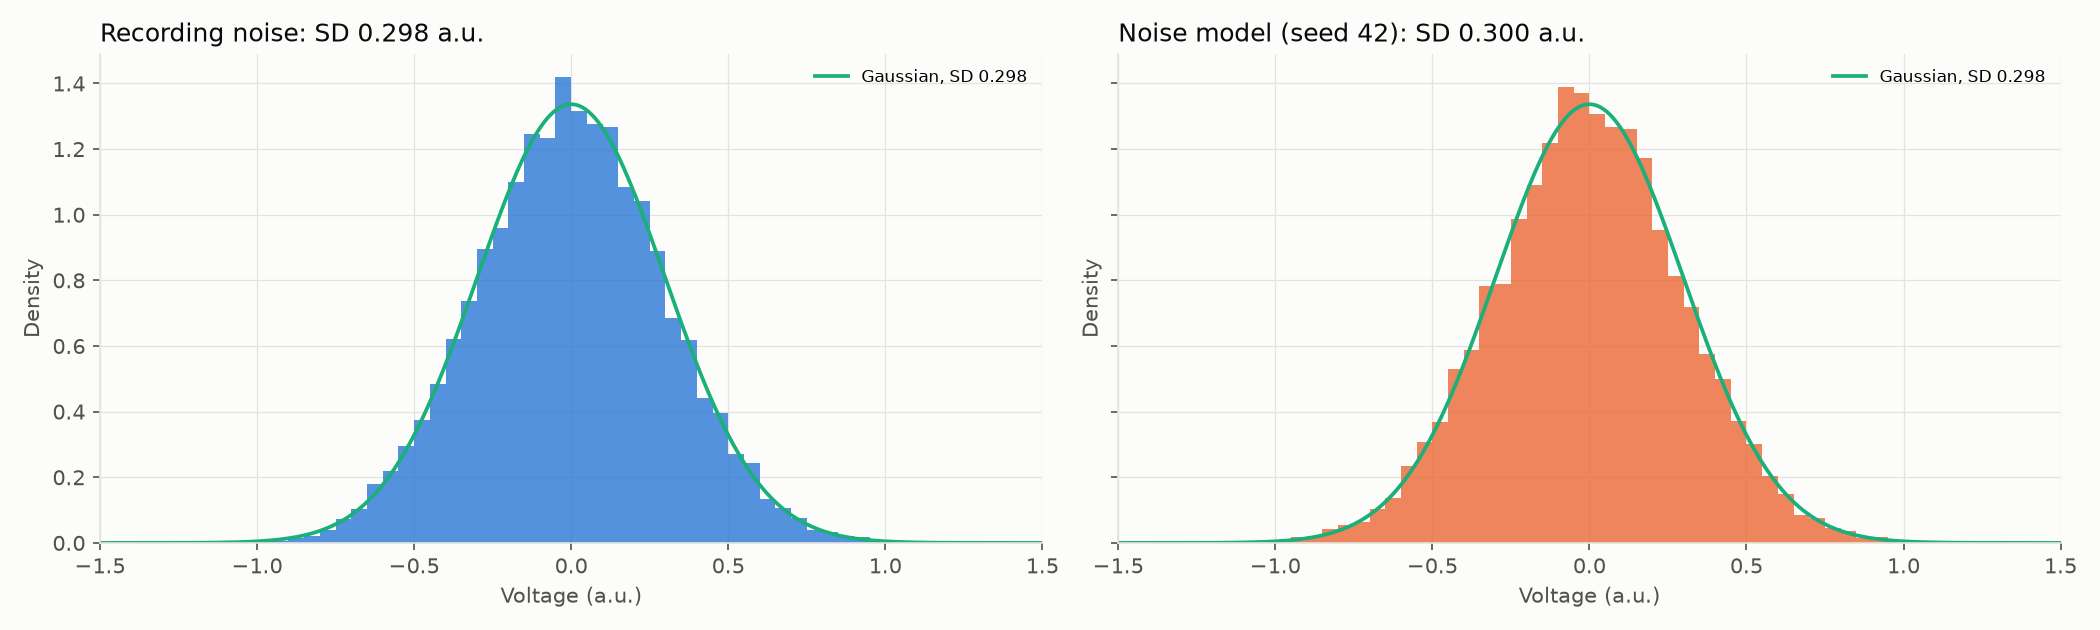


Independence of samples: The noise in the raw data is considered as white noise because the correlation between neighbouring samples is -0.02, about 0, so each sample doesn't, depend on the one before, meaning that the samples are independent in turn indicating that we are dealing with white noise.

Stationary standard deviation over time: the SD is 0.30 in every 2.5 s part of the recording, thus one sigma fits the whole trace.

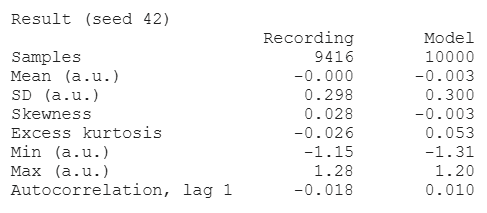

The model matches the recording noise on every measure. Min and max change from seed to seed, because they depend on
a few extreme samples.

In [ ]:
import argparse
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

HERE = Path(__file__).resolve().parent
sys.path.insert(0, str(HERE.parent / "drift"))
from drift_model import X_TICK_STEP, YLIM, fit_drift, sine, spike_mask  # noqa: E402

sys.path.insert(0, str(HERE.parents[1] / "Part 5"))
from common import (DETRENDED_COLOR, RAW_COLOR, REFRACTORY_MS, SURFACE, TEXT_PRIMARY, THRESHOLD, detect_spikes,  # noqa: E402
                    load, refractory_samples_from, style_axis)

SEED = 42
PANEL_HEIGHT = 2.8
HIST_BINS = 60
HIST_RANGE = (-1.5, 1.5)
GAUSS_COLOR = "#1baf7a"


def real_noise(t, x):
    # Raw voltage minus the fitted drift; samples around spikes are NaN so only the noise is left.
    idx = detect_spikes(x, THRESHOLD, refractory_samples_from(t, REFRACTORY_MS))
    keep = spike_mask(t.size, idx)
    params, _ = fit_drift(t, x, keep)
    return np.where(keep, x - sine(t, *params), np.nan), idx.size


def fit_noise(real):
    return real[~np.isnan(real)].std(ddof=1)


def describe(y):
    y = y[~np.isnan(y)]
    lag1 = np.corrcoef(y[:-1], y[1:])[0, 1]
    return [
        f"{y.size}",
        f"{y.mean():.3f}",
        f"{y.std(ddof=1):.3f}",
        f"{stats.skew(y):.3f}",
        f"{stats.kurtosis(y):.3f}",
        f"{y.min():.2f}",
        f"{y.max():.2f}",
        f"{lag1:.3f}",
    ]


ROWS = ["Samples", "Mean (a.u.)", "SD (a.u.)", "Skewness", "Excess kurtosis", "Min (a.u.)", "Max (a.u.)",
        "Autocorrelation, lag 1"]


def finish(ax, t, title):
    ax.set_title(title, color=TEXT_PRIMARY, loc="left")
    ax.set_xlim(t[0], t[-1] + (t[1] - t[0]))
    ax.set_xticks(np.arange(0, t[-1] + X_TICK_STEP, X_TICK_STEP))
    ax.set_ylim(*YLIM)
    style_axis(ax, "Time (s)", "Voltage (a.u.)")


def save(fig, name, seed):
    # Default seed keeps the plain file names; any other seed gets its own files instead of overwriting them.
    if seed != SEED:
        name = name.replace(".png", f"_seed{seed}.png")
    fig.tight_layout()
    fig.savefig(HERE / name, dpi=150)
    print(f"Saved {name}")


def main():
    parser = argparse.ArgumentParser(description="Fit and simulate the noise as Gaussian white noise.")
    parser.add_argument("--seed", type=int, default=SEED)
    args = parser.parse_args()

    t, x = load()
    real, n_spikes = real_noise(t, x)
    clean = real[~np.isnan(real)]
    sigma = fit_noise(real)
    sim = np.random.default_rng(args.seed).normal(0, sigma, t.size)

    print(f"Noise model           Gaussian, mean 0, SD {sigma:.3f} a.u., independent samples (seed {args.seed})")
    print(f"Real noise            raw voltage minus fitted drift, {np.isnan(real).sum()} samples around "
          f"{n_spikes} spikes removed")
    print()
    print(f"Normality tests on the real noise (p > 0.05: no evidence against Gaussian)")
    print(f"  D'Agostino-Pearson  p = {stats.normaltest(clean).pvalue:.2f}")
    print(f"  Kolmogorov-Smirnov  p = {stats.kstest(clean, 'norm', args=(0, sigma)).pvalue:.2f}")
    print()
    table = [describe(real), describe(sim)]
    width = max(len(r) for r in ROWS)
    print(f"{'':<{width}}{'Recording':>12}{'Model':>12}")
    for i, row in enumerate(ROWS):
        print(f"{row:<{width}}{table[0][i]:>12}{table[1][i]:>12}")
    print()

    model_title = f"Noise model: Gaussian, mean 0, SD {sigma:.3f} a.u. (seed {args.seed})"
    real_title = "Recording noise: raw voltage minus fitted drift, spikes removed"

    fig, axes = plt.subplots(3, 1, figsize=(14, PANEL_HEIGHT * 3 + 0.6), facecolor=SURFACE)
    axes[0].plot(t, x, color=RAW_COLOR, linewidth=0.6)
    finish(axes[0], t, "Recording, full raw voltage")
    axes[1].plot(t, real, color=RAW_COLOR, linewidth=0.6)
    finish(axes[1], t, real_title)
    axes[2].plot(t, sim, color=DETRENDED_COLOR, linewidth=0.6)
    finish(axes[2], t, model_title)
    save(fig, "noise_side_by_side.png", args.seed)

    fig, ax = plt.subplots(figsize=(14, PANEL_HEIGHT + 0.6), facecolor=SURFACE)
    ax.plot(t, real, color=RAW_COLOR, linewidth=0.6, label="Recording noise")
    ax.plot(t, sim, color=DETRENDED_COLOR, linewidth=0.6, alpha=0.6, label="Noise model")
    finish(ax, t, "Recording noise vs noise model")
    ax.legend(loc="upper right", frameon=False, ncol=2, fontsize=8)
    save(fig, "noise_overlay.png", args.seed)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True, facecolor=SURFACE)
    grid = np.linspace(*HIST_RANGE, 300)
    for ax, data, color, title in [(axes[0], clean, RAW_COLOR, "Recording noise"),
                                   (axes[1], sim, DETRENDED_COLOR, f"Noise model (seed {args.seed})")]:
        ax.hist(data, bins=HIST_BINS, range=HIST_RANGE, density=True, color=color, alpha=0.8)
        ax.plot(grid, stats.norm.pdf(grid, 0, sigma), color=GAUSS_COLOR, linewidth=1.8,
                label=f"Gaussian, SD {sigma:.3f}")
        ax.set_title(f"{title}: SD {data.std(ddof=1):.3f} a.u.", color=TEXT_PRIMARY, loc="left")
        ax.set_xlim(*HIST_RANGE)
        style_axis(ax, "Voltage (a.u.)", "Density")
        ax.legend(loc="upper right", frameon=False, fontsize=8)
    save(fig, "noise_histogram.png", args.seed)


if __name__ == "__main__":
    main()

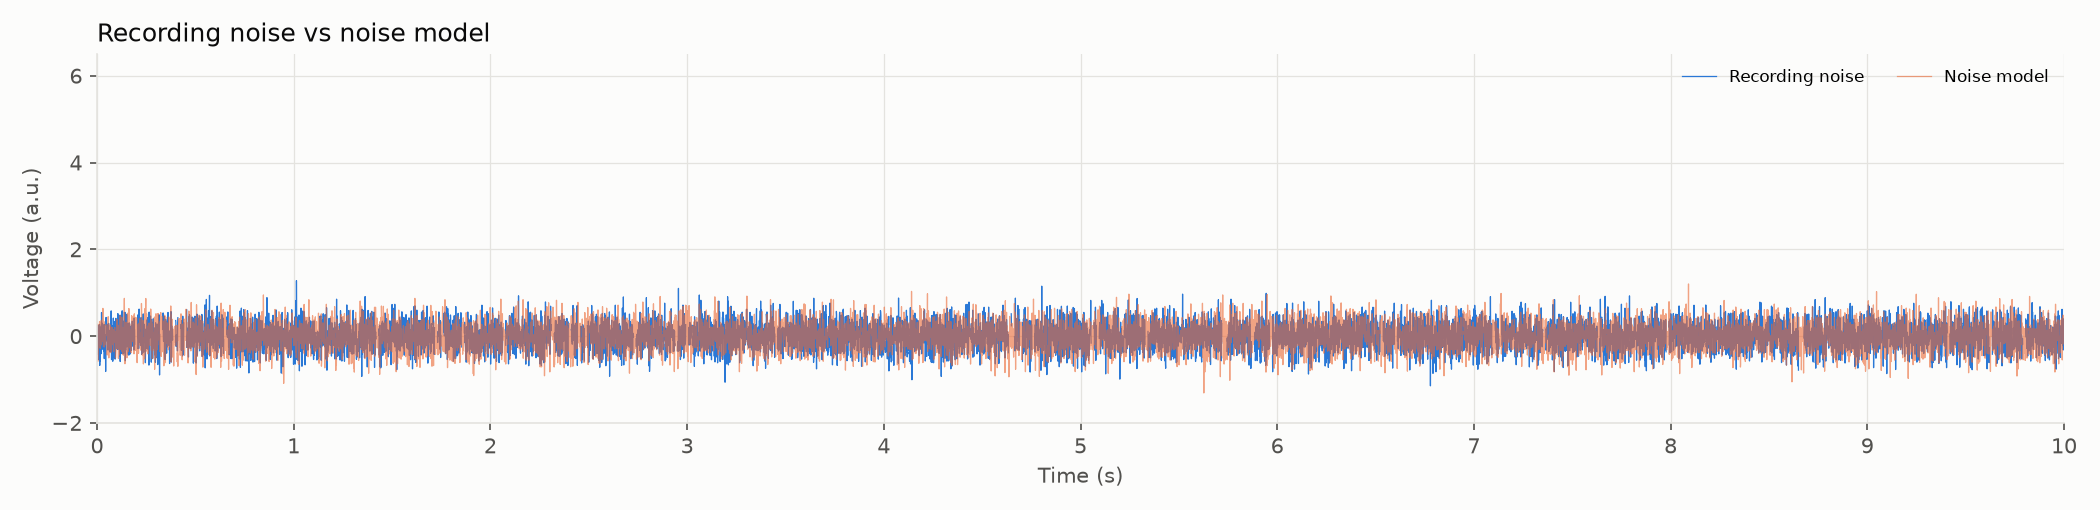

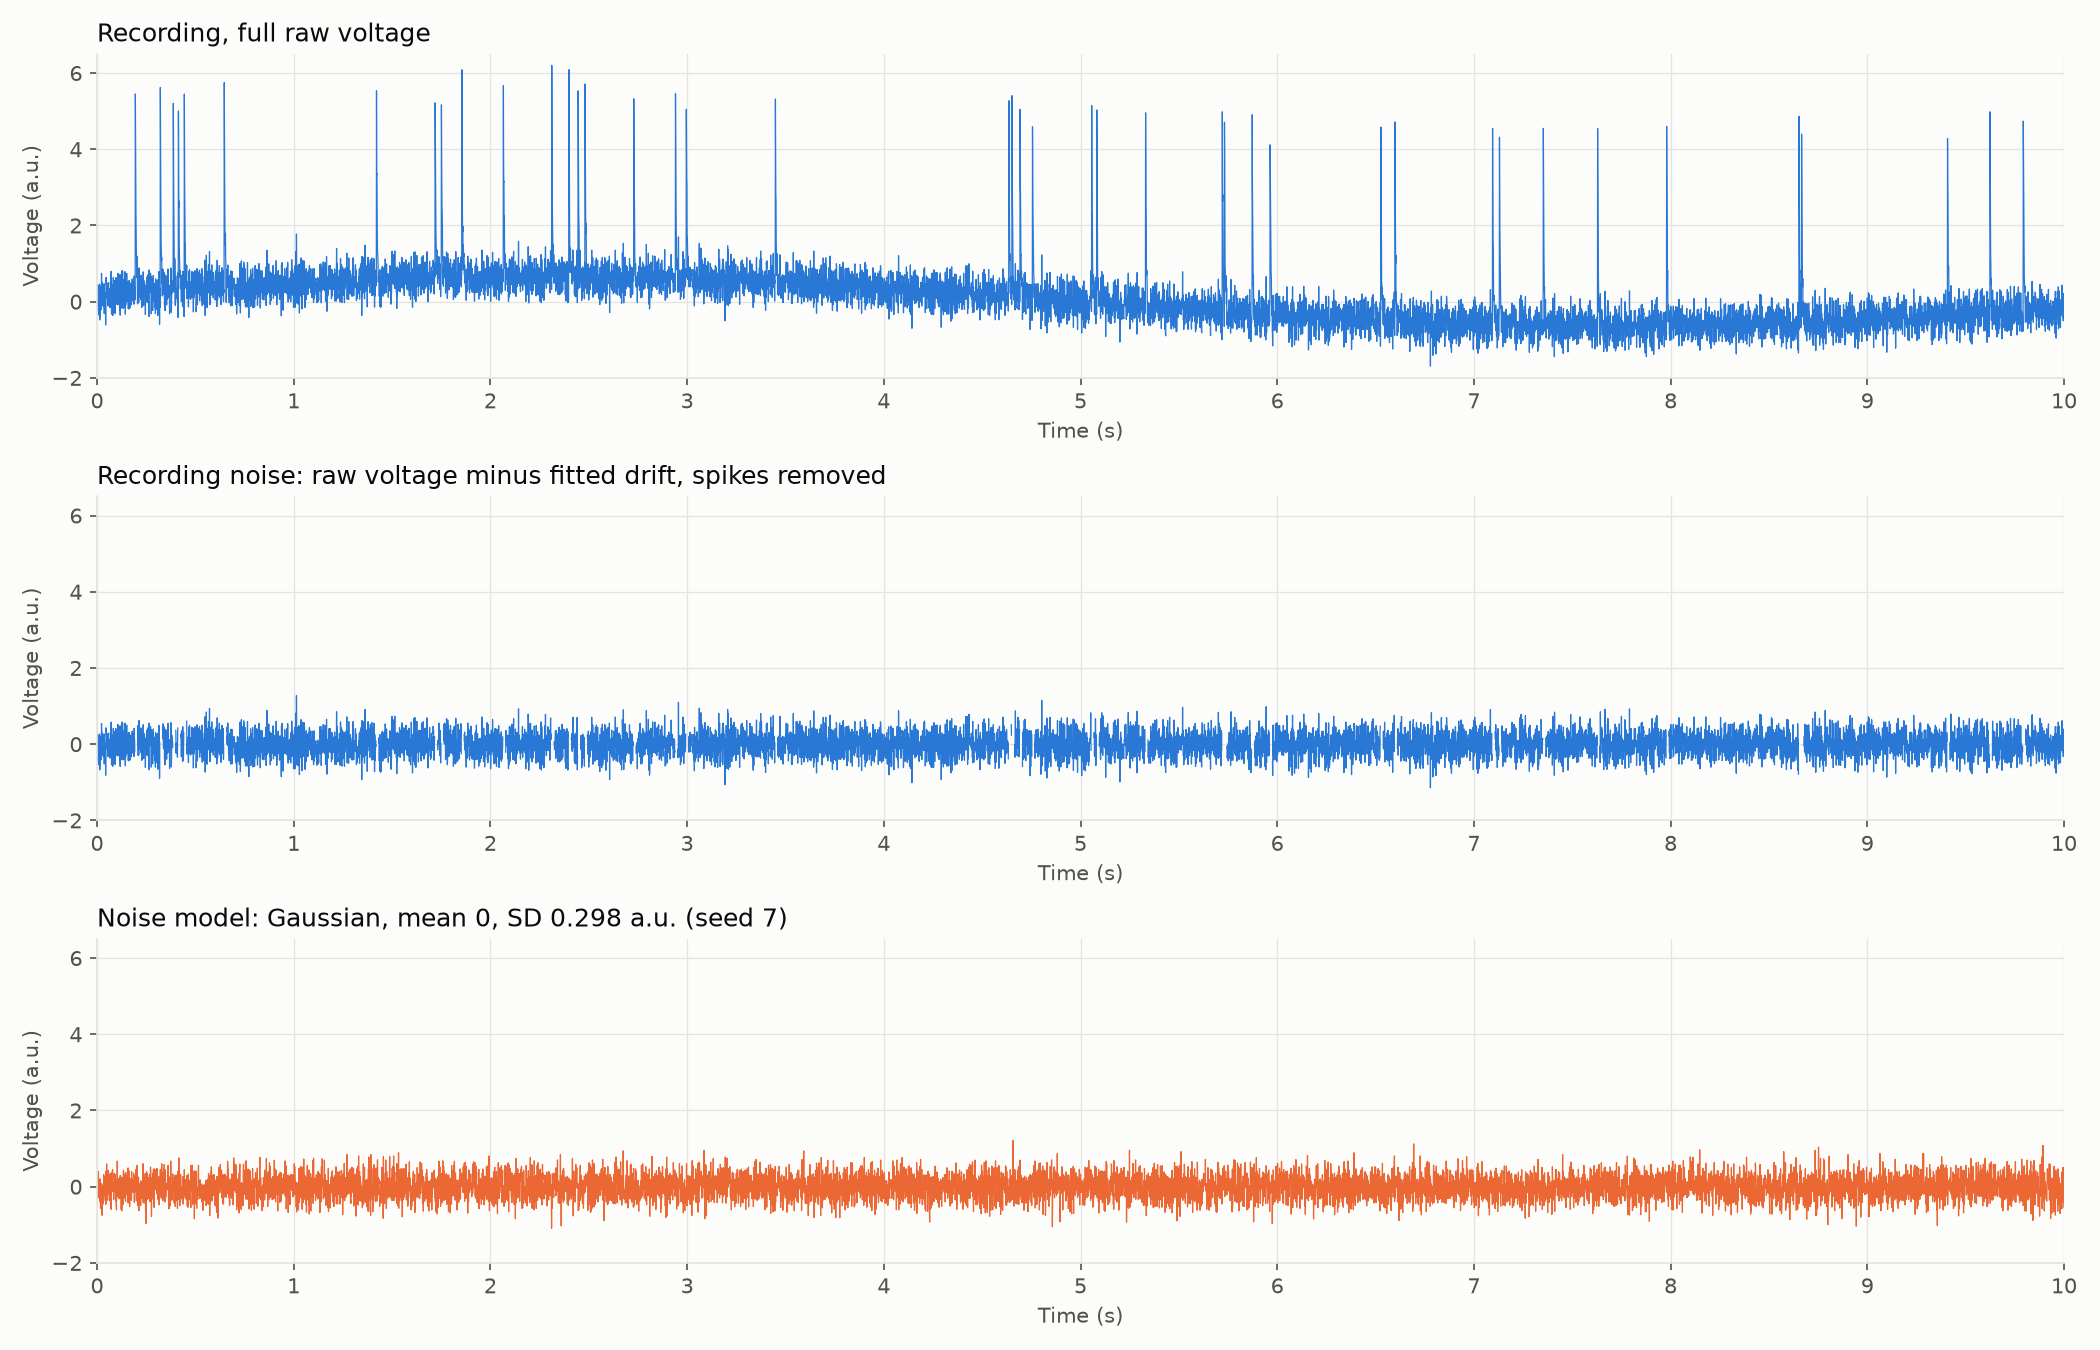

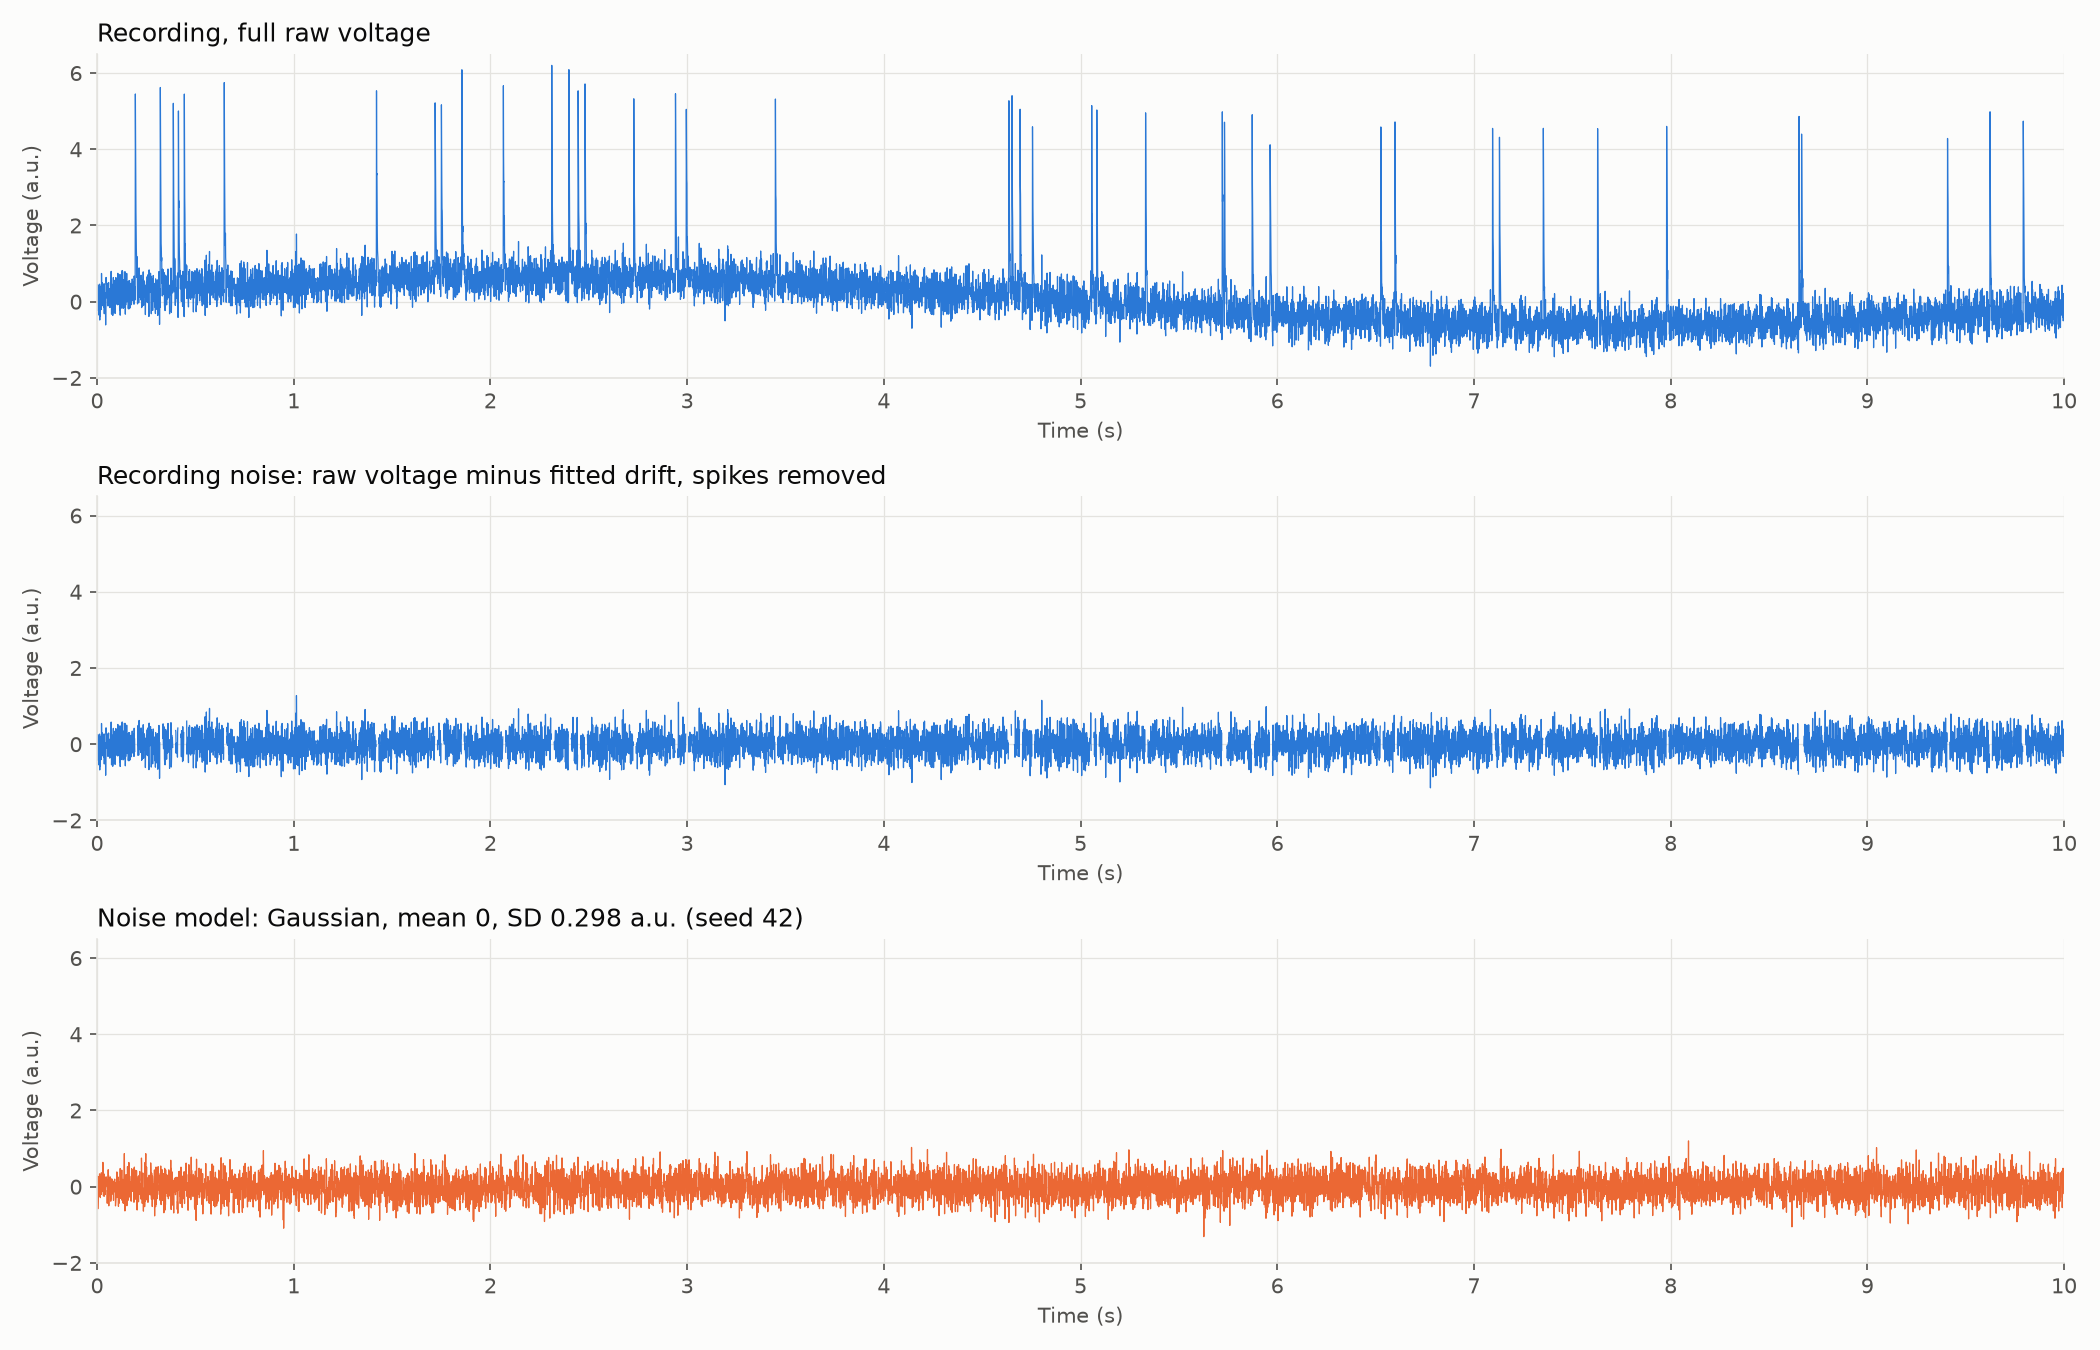

# **Full Model**

**Full model (spikes + drift + noise)**

The synthesized signal is the sum of the three parts, each fitted from the recording in its own folder:

  signal(t) = spikes(t) + drift(t) + noise(t)

The synthesized signal is generated by summing three independently parameterized components: signal(t) = spikes(t) + drift(t) + noise(t). The action potentials, spikes(t), are modeled with an exponential decay waveform of V(t) = 5.00 exp(-t / 2.94 ms) for t >= 0, whose onset times follow a piecewise Poisson process evaluated at 4.6 Hz for the first 5 seconds and 3.8 Hz for the remaining 5 seconds, subject to a 5 ms refractory dead time (seed = 0). The underlying baseline drift is captured by a low-frequency sine wave, drift(t) = 0.648 sin(2*pi * 0.0908 * t + 0.29) , corresponding to an 11.02 s oscillation period. Finally, the background disturbance is modeled as independent, zero-mean Gaussian white noise, noise(t), with a standard deviation of sigma = 0.298 a.u. generated using a fixed pseudorandom initialization (seed = 42).


full_model.py fits all coefficients again from the raw data when it runs (it calls the fit functions from spikes/,
drift/ and noise/), so nothing is copied by hand.

Comparison with the recording (results.txt)
The overall numbers are very close: mean 0.077 vs 0.078, SD 0.734 vs 0.727, min -1.69 vs -1.54, max 6.20 vs 6.06.
The Part 4 detector (threshold 3, 5 ms) finds 44 spikes in the model, the same number that was generated, compared
with 42 in the recording. A two-sample KS test on all 10,000 voltage values finds no difference between the two
distributions (D = 0.014, p = 0.27). The histograms have the same shape: a wide noise band from about -1.5 to 1.5
(wide because the drift moves it up and down) and a thin tail of spike samples up to about 6.

What doesn't match
The spike times are random, so they are in different places than in the recording. The ISI CV is lower in the
model with these seeds (0.73 vs 1.07), meaning the model's spikes are spread more evenly in this run; this changes
with the spike seed.

In [ ]:
import argparse
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

HERE = Path(__file__).resolve().parent
for part in ("spikes", "drift", "noise"):
    sys.path.insert(0, str(HERE.parent / part))
import spike_model  # noqa: E402
import noise_model  # noqa: E402
from drift_model import X_TICK_STEP, YLIM, fit_drift, sine, spike_mask  # noqa: E402
from noise_model import fit_noise  # noqa: E402
from spike_model import PEAK_SEARCH, fit_waveform, simulate, spike_train  # noqa: E402

sys.path.insert(0, str(HERE.parents[1] / "Part 5"))
from common import (DETRENDED_COLOR, RAW_COLOR, REFRACTORY_MS, SURFACE, TEXT_PRIMARY, THRESHOLD, baseline,  # noqa: E402
                    detect_spikes, load, refractory_samples_from, sampling_interval, style_axis)

PANEL_HEIGHT = 2.8
HIST_BINS = 120
HIST_RANGE = (-2, 6.5)


def fit_signal(t, x):
    # Same steps as the spikes/, drift/ and noise/ scripts, but on any signal, so the tests can refit synthetic data.
    dt = sampling_interval(t)
    idx = detect_spikes(x, THRESHOLD, refractory_samples_from(t, REFRACTORY_MS))
    y = x - baseline(t, x)
    peaks = np.array([i + np.argmax(y[i:i + PEAK_SEARCH]) for i in idx], dtype=int)
    amplitude, tau = fit_waveform(y, peaks, dt)
    keep = spike_mask(t.size, idx)
    drift, _ = fit_drift(t, x, keep)
    sigma = fit_noise(np.where(keep, x - sine(t, *drift), np.nan))
    return peaks, dt, t.size * dt, amplitude, tau, drift, sigma


def fit_all():
    t, x = load()
    return (t, x, *fit_signal(t, x))


def synthesize(t, peaks, dt, duration, amplitude, tau, drift, sigma, window_s, spike_seed, noise_seed):
    rates, times = simulate(t[peaks], duration, window_s, REFRACTORY_MS / 1e3, np.random.default_rng(spike_seed))
    spikes = spike_train(times, t.size, dt, amplitude, tau)
    noise = np.random.default_rng(noise_seed).normal(0, sigma, t.size)
    return spikes + sine(t, *drift) + noise, rates, times


def describe(t, x):
    idx = detect_spikes(x, THRESHOLD, refractory_samples_from(t, REFRACTORY_MS))
    noise = x[spike_mask(t.size, idx)]
    isi = np.diff(t[idx]) * 1e3
    return [
        f"{x.min():.2f}",
        f"{x.max():.2f}",
        f"{x.mean():.3f}",
        f"{np.median(x):.3f}",
        f"{x.std(ddof=1):.3f}",
        f"{idx.size}",
        f"{idx.size / (t.size * (t[1] - t[0])):.2f}",
        f"{isi.mean():.0f}",
        f"{isi.std() / isi.mean():.2f}",
        f"{noise.std(ddof=1):.3f}",
    ]


ROWS = ["Min (a.u.)", "Max (a.u.)", "Mean (a.u.)", "Median (a.u.)", "SD (a.u.)",
        f"Spikes detected (threshold {THRESHOLD:g}, {REFRACTORY_MS:g} ms)", "Rate (Hz)", "ISI mean (ms)", "ISI CV",
        "SD without spikes, drift left in (a.u.)"]


def finish(ax, t, title):
    ax.set_title(title, color=TEXT_PRIMARY, loc="left")
    ax.set_xlim(t[0], t[-1] + (t[1] - t[0]))
    ax.set_xticks(np.arange(0, t[-1] + X_TICK_STEP, X_TICK_STEP))
    ax.set_ylim(*YLIM)
    style_axis(ax, "Time (s)", "Voltage (a.u.)")


def save(fig, name):
    fig.tight_layout()
    fig.savefig(HERE / name, dpi=150)
    print(f"Saved {name}")


def main():
    parser = argparse.ArgumentParser(description="Synthesize the full signal (spikes + drift + noise) from the model.")
    parser.add_argument("--window-s", type=float, default=spike_model.WINDOW_S)
    parser.add_argument("--spike-seed", type=int, default=spike_model.SEED)
    parser.add_argument("--noise-seed", type=int, default=noise_model.SEED)
    args = parser.parse_args()

    t, x, peaks, dt, duration, amplitude, tau, drift, sigma = fit_all()
    if not 0 < args.window_s <= duration:
        parser.error(f"--window-s must be between 0 and {duration:g} s")
    synth, rates, times = synthesize(t, peaks, dt, duration, amplitude, tau, drift, sigma, args.window_s,
                                     args.spike_seed, args.noise_seed)

    a_d, f_d, p_d, c_d = drift
    print("Model coefficients (all fitted from the recording)")
    print(f"  Spikes   A {amplitude:.2f} a.u., tau {tau * 1e3:.2f} ms, {args.window_s:g} s windows at "
          f"{', '.join(f'{r:.1f}' for r in rates)} Hz, dead time {REFRACTORY_MS:g} ms (seed {args.spike_seed})")
    print(f"  Drift    {a_d:.3f} sin(2 pi {f_d:.4f} t + {p_d:.2f}) + {c_d:.3f}  (period {1 / f_d:.2f} s)")
    print(f"  Noise    Gaussian, mean 0, SD {sigma:.3f} a.u. (seed {args.noise_seed})")
    print(f"  Spikes generated: {times.size}")
    print()
    table = [describe(t, x), describe(t, synth)]
    width = max(len(r) for r in ROWS)
    print(f"{'':<{width}}{'Recording':>12}{'Model':>12}")
    for i, row in enumerate(ROWS):
        print(f"{row:<{width}}{table[0][i]:>12}{table[1][i]:>12}")
    ks = stats.ks_2samp(x, synth)
    print()
    print(f"Two-sample KS test on all voltage values: D = {ks.statistic:.3f}, p = {ks.pvalue:.2f}")
    print()

    model_title = f"Model: spikes + drift + noise (spike seed {args.spike_seed}, noise seed {args.noise_seed})"
    fig, axes = plt.subplots(2, 1, figsize=(14, PANEL_HEIGHT * 2 + 0.6), facecolor=SURFACE)
    axes[0].plot(t, x, color=RAW_COLOR, linewidth=0.6)
    finish(axes[0], t, "Recording, full raw voltage")
    axes[1].plot(t, synth, color=DETRENDED_COLOR, linewidth=0.6)
    finish(axes[1], t, model_title)
    save(fig, "full_side_by_side.png")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True, facecolor=SURFACE)
    for ax, data, color, title in [(axes[0], x, RAW_COLOR, "Recording"), (axes[1], synth, DETRENDED_COLOR, "Model")]:
        ax.hist(data, bins=HIST_BINS, range=HIST_RANGE, color=color, alpha=0.8)
        ax.set_yscale("log")
        ax.set_title(f"{title}: all voltage values", color=TEXT_PRIMARY, loc="left")
        ax.set_xlim(*HIST_RANGE)
        style_axis(ax, "Voltage (a.u.)", "Samples (log scale)")
    save(fig, "full_histogram.png")


if __name__ == "__main__":
    main()
Mostrando full_model_explaination.txt.

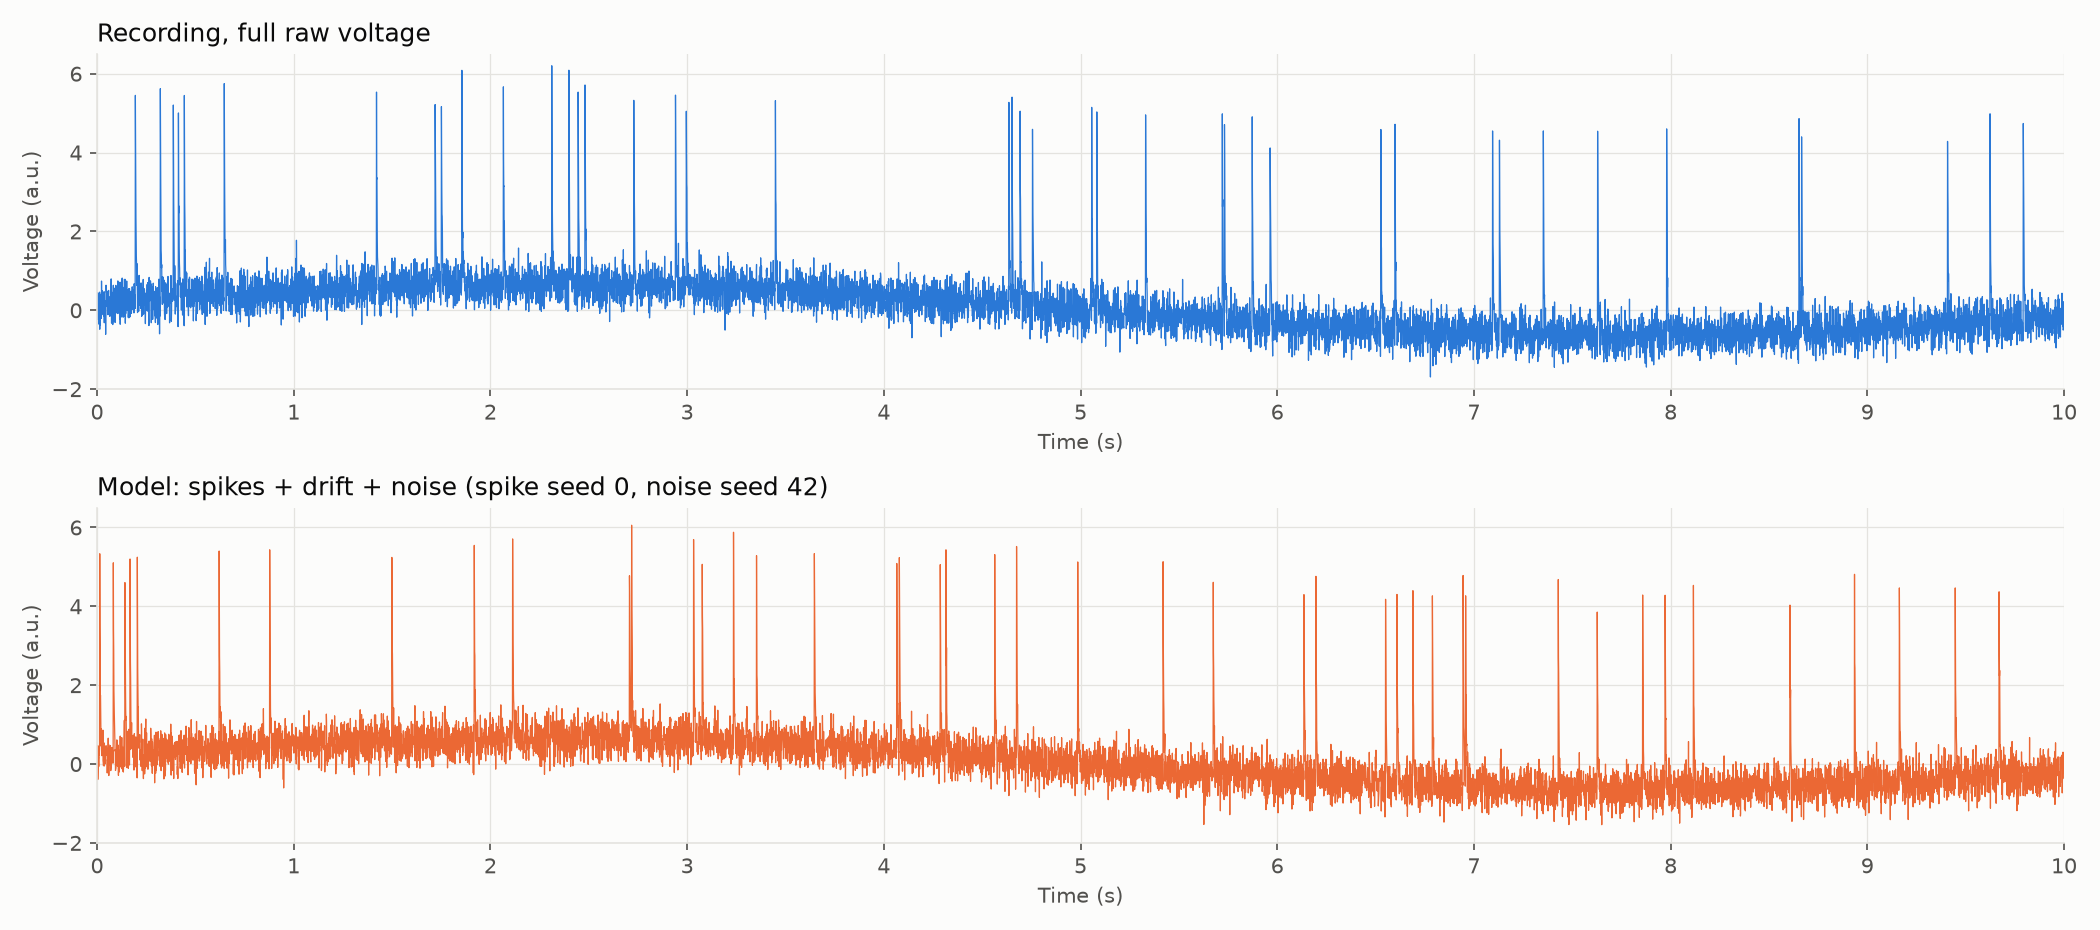

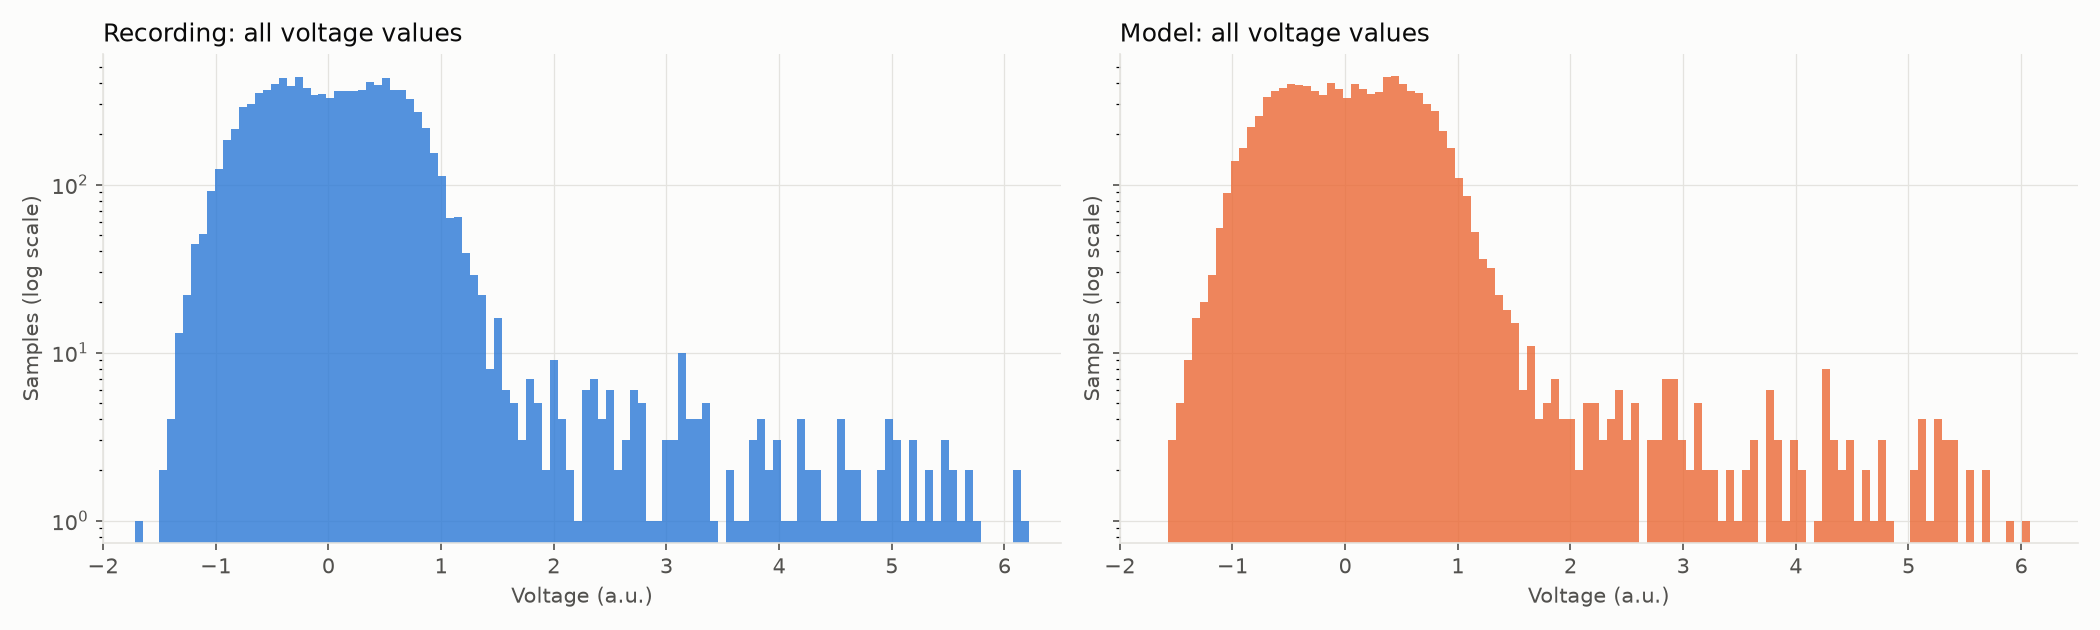

Model coefficients (all fitted from the recording)
  Spikes   A 5.00 a.u., tau 2.94 ms, 5 s windows at 4.6, 3.8 Hz, dead time 5 ms (seed 0)
  Drift    0.648 sin(2 pi 0.0908 t + 0.29) + 0.005  (period 11.02 s)
  Noise    Gaussian, mean 0, SD 0.298 a.u. (seed 42)
  Spikes generated: 44

  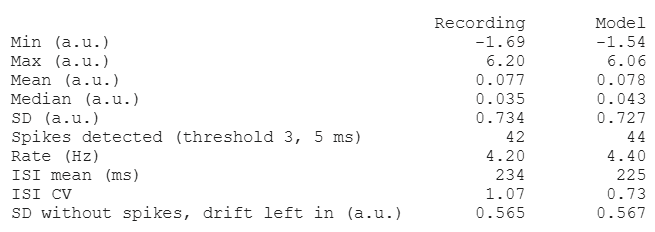

How the model was tested

The model was tested in 3 layers:
1. **Unitesting**: We started off with basic unitesting (testing small functions on dedicated inputs to check sanity and edge cases).

2. **Parameter recovery**: This is the main event! the best way to test that our model actually succeeds in extracting the parameters of a given recording, is to compare the output values against an 'expected' result. The way to do that is generating synthesized data from a set of initalized parameters (spike A = 5, tau = 3 ms, drift 0.65 sin(2 pi 0.09 t + 0.3), noise SD 0.3), running our model to extract the parameters from the synthesized recording, and compare the real initialized parameters against the extracted ones. Because this is stochastic, we added a tolerance parameter - about 4 standard deviations of its spread across seeds.

Additionally, we ran Monte Carlo simulation with 2000 runs - verified that the Poisson spike generator reproduces the expected spike count and theoretical Poisson variance, even with our refractory dead times.

3. **Round trip**: To really make sure our model correctly works on the original recording data, and not only for fake initialized parameters, we ran a third test - extracted the values from the original recording, generated a synthesized data, extracted the values from it, and compared them (with the same tolerance). This is basically like layer 2, but the parameters aren't being generated, they are being extracted from the original data using our model.



In [ ]:
import sys
from pathlib import Path

import numpy as np

from test_model import DT, N, RECOVERY_SEEDS, T, TOL, TRUE, WINDOW_S, synthetic

sys.path.insert(0, str(Path(__file__).resolve().parent.parent / "full_model"))
from full_model import fit_all, fit_signal, synthesize  # noqa: E402

NAMES = ["Spike amplitude A (a.u.)", "Spike decay tau (ms)", "Drift amplitude (a.u.)", "Drift frequency (Hz)",
         "Drift phase (rad)", "Drift offset (a.u.)", "Noise SD sigma (a.u.)"]
FORMATS = ["{:.3f}", "{:.3f}", "{:.4f}", "{:.5f}", "{:.3f}", "{:.4f}", "{:.4f}"]


def flat(amplitude, tau, drift, sigma):
    return [amplitude, tau * 1e3, *drift, sigma]


def table(header, rows):
    width = max(len(n) for n in NAMES)
    print(f"{'':<{width}}" + "".join(f"{h:>14}" for h in header))
    for i, name in enumerate(NAMES):
        print(f"{name:<{width}}" + "".join(f"{r[i]:>14}" for r in rows))


def main():
    true = flat(TRUE["amplitude"], TRUE["tau"], TRUE["drift"], TRUE["sigma"])
    tol = flat(TOL["amplitude"], TOL["tau"], TOL["drift"], TOL["sigma"])

    fits = []
    for s in RECOVERY_SEEDS:
        _, _, _, amplitude, tau, drift, sigma = fit_signal(T, synthetic(s, 100 + s)[0])
        fits.append(flat(amplitude, tau, drift, sigma))
    fits = np.array(fits)
    worst = np.abs(fits - true).max(axis=0)

    print(f"1. Parameter recovery: synthetic signals built with known values, then fitted "
          f"({len(RECOVERY_SEEDS)} seeds, {N} samples at {1 / DT:g} Hz)")
    print()
    table(["True", "Fitted mean", "Fitted SD", "Worst error", "Tolerance", "Pass"],
          [[f.format(v) for f, v in zip(FORMATS, true)],
           [f.format(v) for f, v in zip(FORMATS, fits.mean(axis=0))],
           [f.format(v) for f, v in zip(FORMATS, fits.std(axis=0))],
           [f.format(v) for f, v in zip(FORMATS, worst)],
           [f.format(v) for f, v in zip(FORMATS, tol)],
           ["yes" if w <= t else "NO" for w, t in zip(worst, tol)]])
    print()

    t, x, peaks, dt, duration, amplitude, tau, drift, sigma = fit_all()
    synth, _, _ = synthesize(t, peaks, dt, duration, amplitude, tau, drift, sigma, WINDOW_S, 0, 42)
    _, _, _, a2, tau2, drift2, sigma2 = fit_signal(t, synth)
    real = flat(amplitude, tau, drift, sigma)
    refit = flat(a2, tau2, drift2, sigma2)
    error = np.abs(np.array(refit) - real)

    print("2. Round trip: coefficients fitted from the recording, then refitted from the full model built with them "
          "(spike seed 0, noise seed 42)")
    print()
    table(["Recording", "Model refit", "Error", "Tolerance", "Pass"],
          [[f.format(v) for f, v in zip(FORMATS, real)],
           [f.format(v) for f, v in zip(FORMATS, refit)],
           [f.format(v) for f, v in zip(FORMATS, error)],
           [f.format(v) for f, v in zip(FORMATS, tol)],
           ["yes" if e <= t else "NO" for e, t in zip(error, tol)]])


if __name__ == "__main__":
    main()
Mostrando compare_coefficients.py.

In [ ]:
import sys
import unittest
from pathlib import Path

import numpy as np

HERE = Path(__file__).resolve().parent
for part in ("spikes", "drift", "noise", "full_model"):
    sys.path.insert(0, str(HERE.parent / part))
from drift_model import MASK_AFTER, MASK_BEFORE, sine, spike_mask  # noqa: E402
from full_model import fit_all, fit_signal, synthesize  # noqa: E402
from noise_model import fit_noise  # noqa: E402
from spike_model import decay, poisson_times, spike_train, window_edges, window_rates  # noqa: E402

N = 10_000
DT = 0.001
T = np.arange(N) * DT
DURATION = N * DT
DEAD_TIME = 0.005
WINDOW_S = 5.0
# Known values used to build the synthetic signals; close to the recording's own fit.
TRUE = dict(amplitude=5.0, tau=0.003, drift=(0.65, 0.09, 0.3, 0.0), sigma=0.3, rates=(4.6, 3.8))
RECOVERY_SEEDS = range(10)
# Tolerances are about 4 SD of each fitted value's spread over 20 synthetic runs, so a correct fit passes every time.
TOL = dict(amplitude=0.2, tau=0.0003, drift=(0.015, 0.0015, 0.06, 0.02), sigma=0.008)
RATE_RUNS = 2000


def synthetic(spike_seed, noise_seed):
    edges = window_edges(DURATION, WINDOW_S)
    times = poisson_times(np.array(TRUE["rates"]), edges, DEAD_TIME, np.random.default_rng(spike_seed))
    spikes = spike_train(times, N, DT, TRUE["amplitude"], TRUE["tau"])
    noise = np.random.default_rng(noise_seed).normal(0, TRUE["sigma"], N)
    return spikes + sine(T, *TRUE["drift"]) + noise, times


class TestSmallFunctions(unittest.TestCase):
    def test_sine_known_values(self):
        period = 10.0
        values = sine(np.array([0, period / 4, period / 2]), 2.0, 1 / period, 0.0, 0.5)
        np.testing.assert_allclose(values, [0.5, 2.5, 0.5], atol=1e-12)

    def test_spike_mask_covers_window(self):
        keep = spike_mask(100, [50])
        self.assertEqual(np.flatnonzero(~keep).tolist(), list(range(50 - MASK_BEFORE, 50 + MASK_AFTER)))

    def test_spike_mask_at_signal_edges(self):
        keep = spike_mask(100, [0, 99])
        self.assertEqual(np.flatnonzero(~keep).tolist(), [*range(0, MASK_AFTER), *range(99 - MASK_BEFORE, 100)])

    def test_window_edges_divides(self):
        self.assertEqual(window_edges(10.0, 5.0).tolist(), [0, 5, 10])

    def test_window_edges_leftover(self):
        self.assertEqual(window_edges(10.0, 3.0).tolist(), [0, 3, 6, 9, 10])

    def test_window_rates(self):
        times = np.array([0.5, 1.0, 1.5, 6.0])
        self.assertEqual(window_rates(times, np.array([0, 5, 10])).tolist(), [0.6, 0.2])

    def test_spike_train_shape(self):
        x = spike_train(np.array([0.1]), 200, DT, 5.0, 0.003)
        self.assertAlmostEqual(x[100], 5.0)
        self.assertEqual(x[:100].tolist(), [0] * 100)
        np.testing.assert_allclose(x[101:105] / x[100:104], np.exp(-1 / 3))

    def test_spike_train_close_spikes_add(self):
        x = spike_train(np.array([0.1, 0.102]), 200, DT, 5.0, 0.003)
        self.assertAlmostEqual(x[102], 5.0 + float(decay(2, 5.0, 3)))

    def test_poisson_times_respect_dead_time_and_bounds(self):
        times = poisson_times(np.array([50.0, 50.0]), window_edges(DURATION, WINDOW_S), DEAD_TIME,
                              np.random.default_rng(0))
        self.assertGreater(times.size, 100)
        self.assertGreaterEqual(np.diff(times).min(), DEAD_TIME)
        self.assertTrue(((times >= 0) & (times < DURATION)).all())

    def test_fit_noise_ignores_masked_samples(self):
        self.assertAlmostEqual(fit_noise(np.array([1.0, -1.0, np.nan, 1.0, -1.0])), np.std([1, -1, 1, -1], ddof=1))


class TestParameterRecovery(unittest.TestCase):
    def setUp(self):
        self.fits = [fit_signal(T, synthetic(s, 100 + s)[0]) for s in RECOVERY_SEEDS]

    def test_spike_shape_recovered(self):
        for _, _, _, amplitude, tau, _, _ in self.fits:
            self.assertAlmostEqual(amplitude, TRUE["amplitude"], delta=TOL["amplitude"])
            self.assertAlmostEqual(tau, TRUE["tau"], delta=TOL["tau"])

    def test_drift_recovered(self):
        for *_, drift, _ in self.fits:
            for fitted, true, tol in zip(drift, TRUE["drift"], TOL["drift"]):
                self.assertAlmostEqual(fitted, true, delta=tol)

    def test_noise_recovered(self):
        for *_, sigma in self.fits:
            self.assertAlmostEqual(sigma, TRUE["sigma"], delta=TOL["sigma"])

    def test_mean_spike_count_matches_rate(self):
        edges = window_edges(DURATION, WINDOW_S)
        counts = [poisson_times(np.array(TRUE["rates"]), edges, DEAD_TIME, np.random.default_rng(s)).size
                  for s in range(RATE_RUNS)]
        expected = sum(TRUE["rates"]) * WINDOW_S
        # The dead time removes about 1 spike in 42, so the mean sits just below the expected count.
        self.assertAlmostEqual(np.mean(counts), expected, delta=2.0)
        self.assertAlmostEqual(np.std(counts), np.sqrt(expected), delta=1.0)


class TestRoundTrip(unittest.TestCase):
    def test_detector_finds_every_generated_spike(self):
        for s in RECOVERY_SEEDS:
            x, times = synthetic(s, 100 + s)
            peaks = fit_signal(T, x)[0]
            self.assertEqual(peaks.size, times.size)
            np.testing.assert_array_equal(peaks, np.round(times / DT).astype(int))

    def test_refit_of_full_model_returns_recording_coefficients(self):
        t, x, peaks, dt, duration, amplitude, tau, drift, sigma = fit_all()
        synth, _, _ = synthesize(t, peaks, dt, duration, amplitude, tau, drift, sigma, WINDOW_S, 0, 42)
        _, _, _, a2, tau2, drift2, sigma2 = fit_signal(t, synth)
        self.assertAlmostEqual(a2, amplitude, delta=TOL["amplitude"])
        self.assertAlmostEqual(tau2, tau, delta=TOL["tau"])
        for fitted, true, tol in zip(drift2, drift, TOL["drift"]):
            self.assertAlmostEqual(fitted, true, delta=tol)
        self.assertAlmostEqual(sigma2, sigma, delta=TOL["sigma"])


if __name__ == "__main__":
    unittest.main()
Mostrando test_model.py.

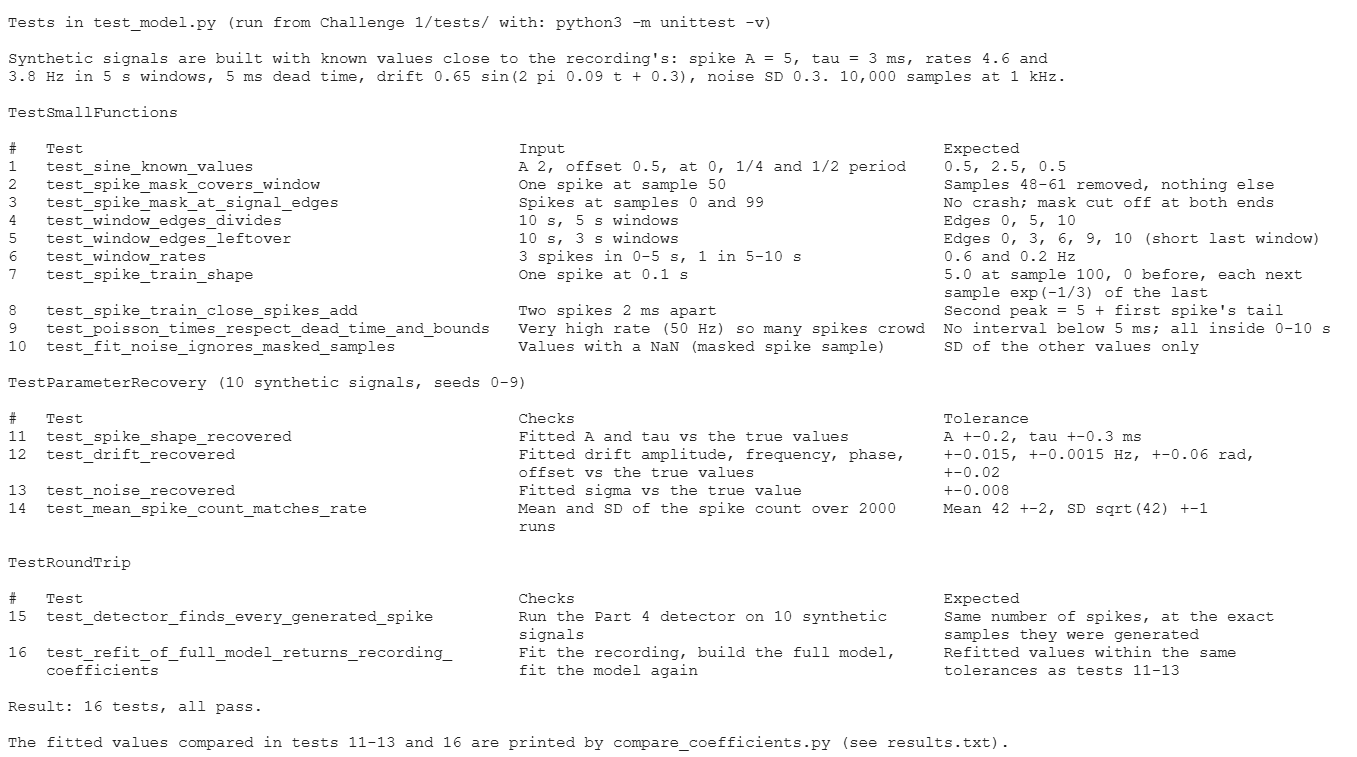

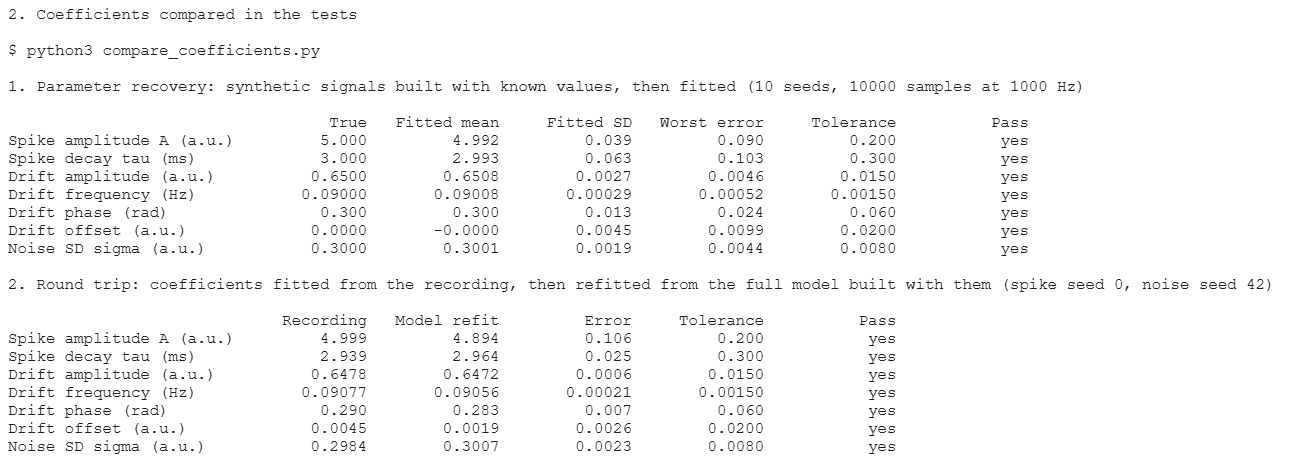